# TP1 — Acquisition, qualité et débruitage d'images avec OpenCV
| Python + OpenCV + NumPy + Matplotlib

## Objectifs
- Observer l'effet de la balance des blancs et comprendre le principe du "monde gris" (Gray World).
- Observer concrètement les effets de la compression JPEG.
- Ajouter différents modèles de bruit : gaussien, Poisson, sel et poivre, et speckle.
- Appliquer des filtres de débruitage avec différents paramètres.
- Étudier l'influence de la taille du noyau et du padding.
- Comparer visuellement les résultats et justifier les choix de paramètres.

> Exécutez les cellules dans l'ordre. Lisez les commentaires: ils expliquent ce que fait chaque ligne. Répondez aux questions dans les cellules "Réponse".

## 1. Installation et préparation

In [1]:
# Installation des bibliothèques
# !pip install opencv-python numpy matplotlib

import cv2
print("Version d'OpenCV :", cv2.__version__)  # Vérifie que l'installation fonctionne

Version d'OpenCV : 5.0.0


Choisissez une image couleur contenant si possible **plusieurs couleurs**, des **zones neutres** (blanc/gris) et des **détails**. Placez-la dans le même dossier que ce notebook, par exemple : `image.jpg`.

> Si vous travaillez sur Google Colab, utilisez le bouton: Fichiers, à gauche pour importer votre image.

## 2. Imports et lecture de l'image

Dimensions (hauteur, largeur, canaux) : (146, 259, 3)
Type des pixels : uint8


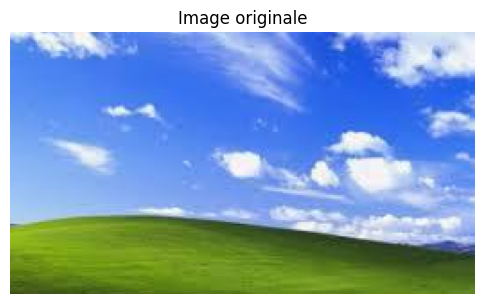

In [31]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Lire l'image avec le bon nom
img_bgr = cv2.imread('/content/i1.jpeg')

# 2. Vérifier que l'image existe
if img_bgr is None:
    raise FileNotFoundError(
        "Image introuvable : vérifiez le chemin du fichier."
    )

# 3. Convertir les couleurs BGR vers RGB
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# 4. Afficher les informations de l'image
print("Dimensions (hauteur, largeur, canaux) :", img.shape)
print("Type des pixels :", img.dtype)

# 5. Afficher l'image
plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.title("Image originale")
plt.axis("off")
plt.show()


### Fonction utilitaire : afficher plusieurs images côte à côte
Cette fonction nous servira tout au long du TP pour comparer des résultats.

In [8]:
def show_images(images, titles, figsize=(15, 4)):
    """Affiche une liste d'images sur une seule ligne, avec leurs titres."""
    n = len(images)                      # Nombre d'images à afficher
    plt.figure(figsize=figsize)
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(1, n, i + 1)         # 1 ligne, n colonnes, position i+1
        plt.imshow(im)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()                   # Évite que les titres se chevauchent
    plt.show()

---
# Partie A — Balance des blancs et monde gris

La balance des blancs cherche à compenser une **dominante de couleur** due à l'éclairage. L'hypothèse du **Gray World** suppose que, pour une scène suffisamment variée, la **moyenne des trois canaux R, G et B** devrait être approximativement la même (la scène moyenne est 'grise').

### A1. Calcul des moyennes RGB

In [27]:
# Moyenne de chaque canal sur toute l'image
# img[:, :, 0] = canal Rouge, img[:, :, 1] = Vert, img[:, :, 2] = Bleu
mean_R = img[:, :, 0].mean()
mean_G = img[:, :, 1].mean()
mean_B = img[:, :, 2].mean()

print(f"Moyennes -> R : {mean_R:.1f} | G : {mean_G:.1f} | B : {mean_B:.1f}")

Moyennes -> R : 145.0 | G : 48.7 | B : 43.3


**Question A1** — Les trois moyennes sont-elles proches ? L'image présente-t-elle une dominante colorée ?

**Réponse A1 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

### A2. Correction Gray World
Principe : on multiplie chaque canal par un gain pour que sa moyenne devienne égale à la moyenne globale (le « gris »).

`gain_canal = gris / moyenne_canal`

mean: [110.60843 148.62297 186.00134]
gray: 148.62297


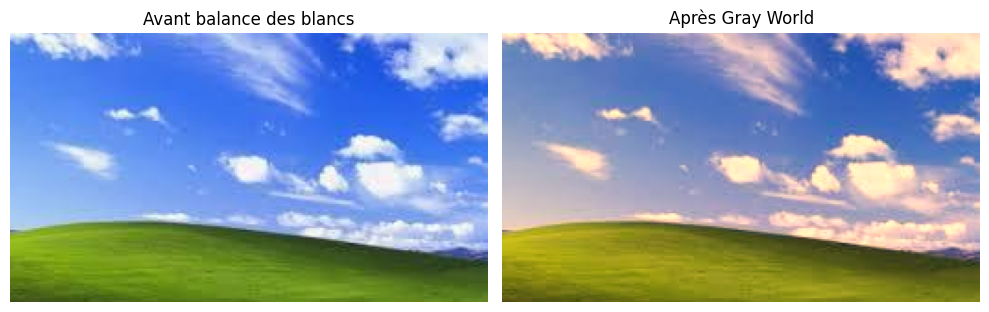

Moyennes après correction (R, G, B) : [144.9 148.6 148. ]


In [33]:
def gray_world(img):
    """Applique la correction de balance des blancs par l'hypothèse du monde gris."""
    img_float = img.astype(np.float32)        # Passage en float pour éviter les dépassements de uint8
    mean = img_float.mean(axis=(0, 1))        # Moyenne de chaque canal -> tableau [mR, mG, mB]
    print("mean:", mean)
    #Comparer les deux techniques moyenne = moyenne des moyennes des 3 canaux Vs. Moy de vert
    gray1 = mean.mean()                        # Valeur de  "gris" cible = moyenne des 3 moyennes
    gray=mean[1]                                # Valeur de "gris" cible = moyenne de vert

    print('gray:', gray)

    result = img_float * (gray / mean)        # Gain appliqué canal par canal (broadcasting NumPy)

    # On limite les valeurs à [0, 255] puis on revient en uint8
    return np.clip(result, 0, 255).astype(np.uint8)

img_wb = gray_world(img) # image après White Balance

show_images([img, img_wb], ["Avant balance des blancs", "Après Gray World"], figsize=(10, 4))

# Vérification : les moyennes après correction doivent être très proches
print("Moyennes après correction (R, G, B) :", img_wb.mean(axis=(0, 1)).round(1))

**Question A2** — La dominante de couleur a-t-elle diminué ? Le résultat est-il nécessairement plus réaliste ? Pourquoi l'hypothèse Gray World peut-elle échouer sur une image contenant beaucoup d'une seule couleur ?

**Réponse A2 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

---
# Partie B — Compression JPEG

OpenCV permet de contrôler la **qualité JPEG** lors de l'encodage (de 0 à 100). Ici, on **compresse puis on décompresse** l'image afin d'observer les artefacts.

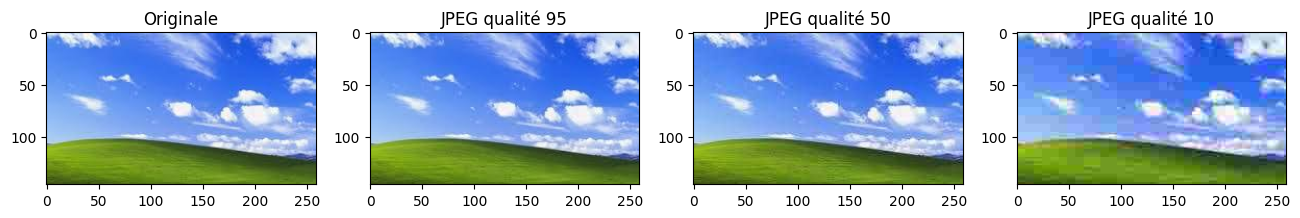

In [41]:
def jpeg_compress(img, quality):
    """Compresse l'image en JPEG avec la qualité donnée, puis la décompresse."""
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)      # OpenCV travaille en BGR

    # imencode "enregistre" l'image en mémoire (sans fichier) au format JPEG
    ok, encoded = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, quality])
    if not ok:
        raise RuntimeError("Échec de l'encodage JPEG")

    # imdecode relit l'image compressée : on obtient l'image AVEC les artefacts
    decoded_bgr = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    return cv2.cvtColor(decoded_bgr, cv2.COLOR_BGR2RGB)

qualities = [95, 50, 10]   # Qualité élevée, moyenne, très faible

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(img)
axes[0].set_title("Originale")

for ax, q in zip(axes[1:], qualities):
    ax.imshow(jpeg_compress(img, q))
    ax.set_title(f"JPEG qualité {q}")


plt.show()

**Astuce :** pour mieux voir les artefacts, zoomez sur une petite zone (contour net, texte, texture).

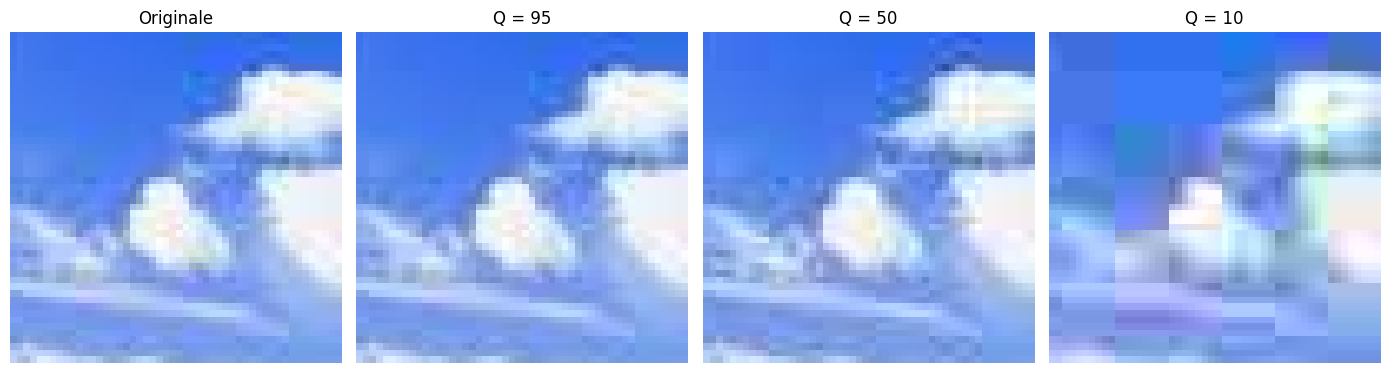

In [44]:
# Zoom sur une zone de l'image : modifiez les indices pour choisir la zone (y1:y2, x1:x2)
y1, y2, x1, x2 = 50, 100, 150, 200

crops = [img[y1:y2, x1:x2]] + [jpeg_compress(img, q)[y1:y2, x1:x2] for q in qualities]
show_images(crops, ["Originale", "Q = 95", "Q = 50", "Q = 10"], figsize=(14, 4))

**Question B1** — Que se passe-t-il lorsque la qualité JPEG diminue ? Où observez-vous le plus facilement les artefacts ?

**Réponse B1 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question B2** — Pourquoi les zones avec contours nets, textures ou détails fins peuvent-elles révéler davantage les artefacts ?

**Réponse B2 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

---
# Partie C — Ajout de bruit

On travaille avec quatre modèles de bruit :
- **Gaussien** et **Poisson** : variations aléatoires d'intensité.
- **Sel et poivre** : pixels aberrants très clairs ou très sombres.
- **Speckle** : bruit *multiplicatif* donnant un aspect granuleux

> Pour obtenir des résultats **reproductibles** (les mêmes à chaque exécution), on fixe la graine du générateur aléatoire.

In [48]:
np.random.seed(42)   # Graine aléatoire : enlevez cette ligne pour avoir un bruit différent à chaque fois

### C1. Bruit gaussien

In [49]:
def add_gaussian_noise(img, mean=0, sigma=20):
    """Ajoute un bruit gaussien (additif) : chaque pixel reçoit une valeur aléatoire N(mean, sigma)."""
    """!!! sigma est l'écart-type du bruit : il contrôle sa force. Plus sigma est grand, plus le bruit est fort"""
    noise = np.random.normal(mean, sigma, img.shape)   # Un tirage aléatoire par pixel et par canal
    noisy = img.astype(np.float32) + noise             # Bruit ADDITIF : image + bruit
    return np.clip(noisy, 0, 255).astype(np.uint8)     # On reste dans [0, 255]



### C2. Bruit sel et poivre

In [50]:
def add_salt_pepper(img, amount=0.03):
    """Met une proportion de pixels à 0 (poivre, noir) et autant à 255 (sel, blanc)."""
    noisy = img.copy()                 # On copie pour ne pas modifier l'image d'origine
    h, w = noisy.shape[:2]

    n = int(amount * h * w)            # Nombre de pixels à corrompre pour chaque couleur

    # Poivre : positions aléatoires mises à 0 (noir)
    ys = np.random.randint(0, h, n)
    xs = np.random.randint(0, w, n)
    noisy[ys, xs] = 0

    # Sel : positions aléatoires mises à 255 (blanc)
    ys = np.random.randint(0, h, n)
    xs = np.random.randint(0, w, n)
    noisy[ys, xs] = 255

    return noisy



### C3. Bruit de Poisson

In [51]:
def add_poisson_noise(img):
    """Bruit de Poisson (bruit de photons) : l'amplitude du bruit dépend de l'intensité du pixel."""
    x = img.astype(np.float32) / 255.0                  # Normalisation entre 0 et 1
    noisy = np.random.poisson(x * 255.0) / 255.0        # Chaque pixel suit une loi de Poisson
    return np.clip(noisy * 255.0, 0, 255).astype(np.uint8)



### C4. Bruit speckle

In [52]:
def add_speckle_noise(img, sigma=0.20):
    """Bruit multiplicatif : le bruit est proportionnel à la valeur du pixel."""
    x = img.astype(np.float32) / 255.0                  # Normalisation entre 0 et 1
    noise = np.random.normal(0, sigma, x.shape)         # Bruit gaussien centré
    noisy = x + x * noise                               # image + image × bruit  (MULTIPLICATIF)
    return np.clip(noisy * 255.0, 0, 255).astype(np.uint8)



### Comparaison visuelle des quatre bruits

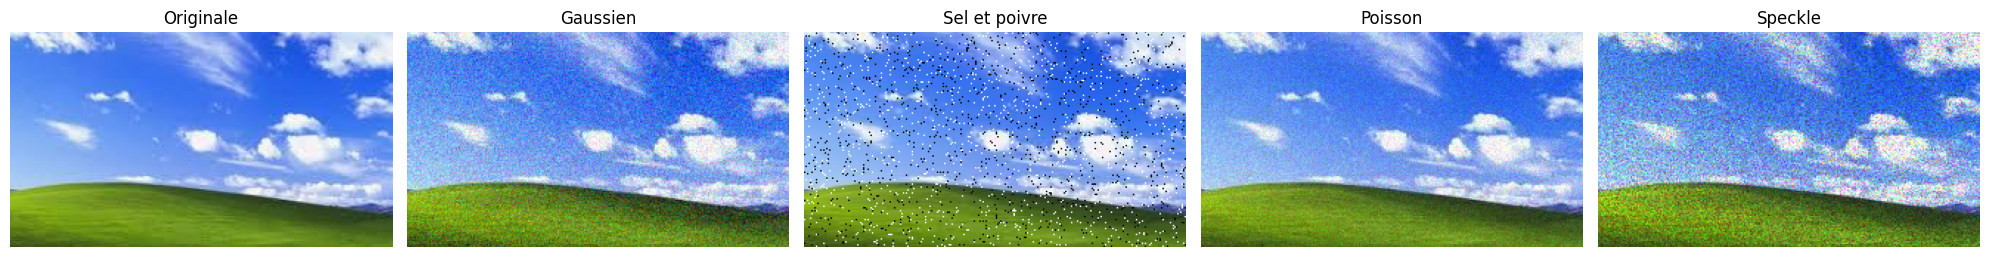

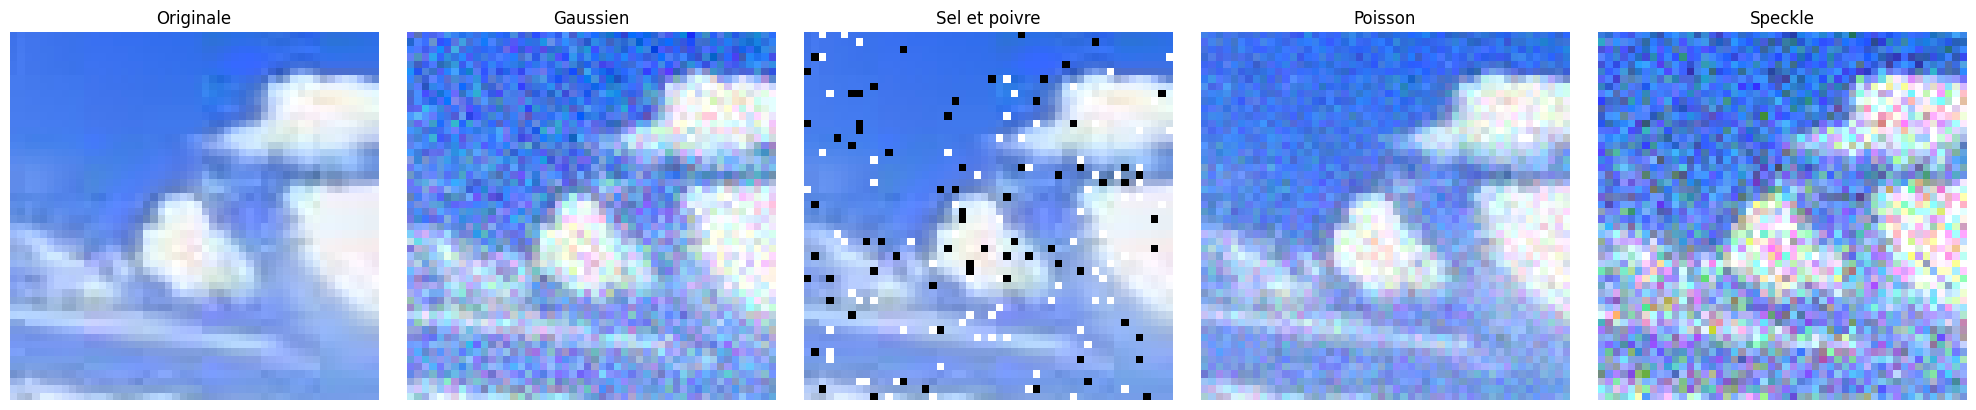

In [55]:
gaussian = add_gaussian_noise(img, sigma=20)   # sigma plus grand = bruit plus fort
salt_pepper = add_salt_pepper(img, amount=0.03)   # 3 % de pixels noirs + 3 % de pixels blancs
poisson = add_poisson_noise(img)
speckle = add_speckle_noise(img, sigma=0.20)


show_images(
    [img, gaussian, salt_pepper, poisson, speckle],
    ["Originale", "Gaussien", "Sel et poivre", "Poisson", "Speckle"],
    figsize=(20, 4)
)

# Zoom sur une petite zone pour mieux voir la nature de chaque bruit
y1, y2, x1, x2 = 50, 100, 150, 200
show_images(
    [im[y1:y2, x1:x2] for im in [img, gaussian, salt_pepper, poisson, speckle]],
    ["Originale", "Gaussien", "Sel et poivre", "Poisson", "Speckle"],
    figsize=(20, 4)
)

In [56]:
def show_images_gray(images, titles, figsize=(15, 4)):
    """Affiche une liste d'images sur une seule ligne, avec leurs titres.
    Pour des images en niveaux de gris, passer cmap="gray"."""
    n = len(images)
    plt.figure(figsize=figsize)
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(1, n, i + 1)
        # vmin/vmax fixent l'échelle de 0 à 255 : sans cela, matplotlib étire
        # le contraste sur chaque image, ce qui fausse la comparaison.
        # (Ignorés pour les images couleur RGB.)
        plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Dimensions de l'image grise : (146, 259)


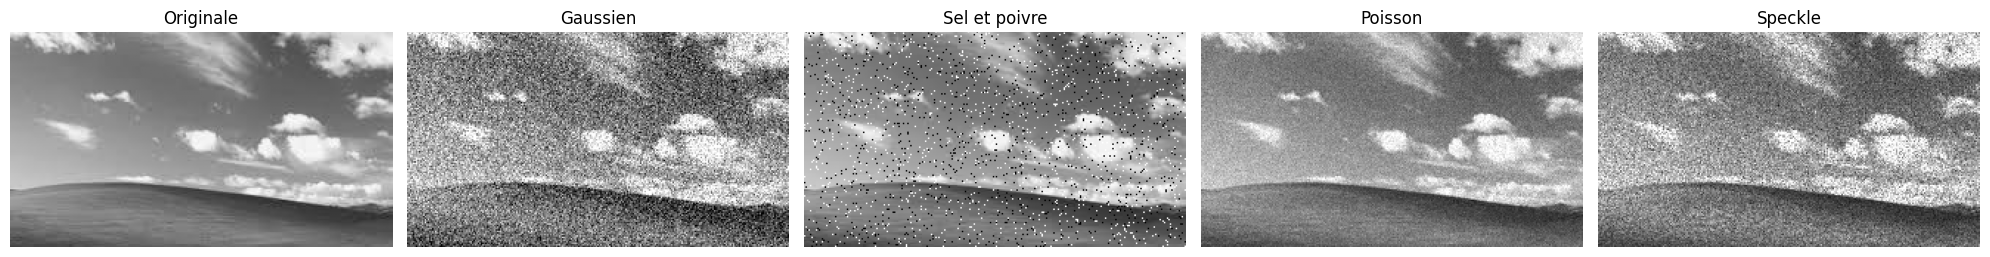

/tmp/ipykernel_688/2408444436.py:11: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  plt.imshow(im, cmap='gray', vmin=0, vmax=255)
/tmp/ipykernel_688/2408444436.py:11: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  plt.imshow(im, cmap='gray', vmin=0, vmax=255)


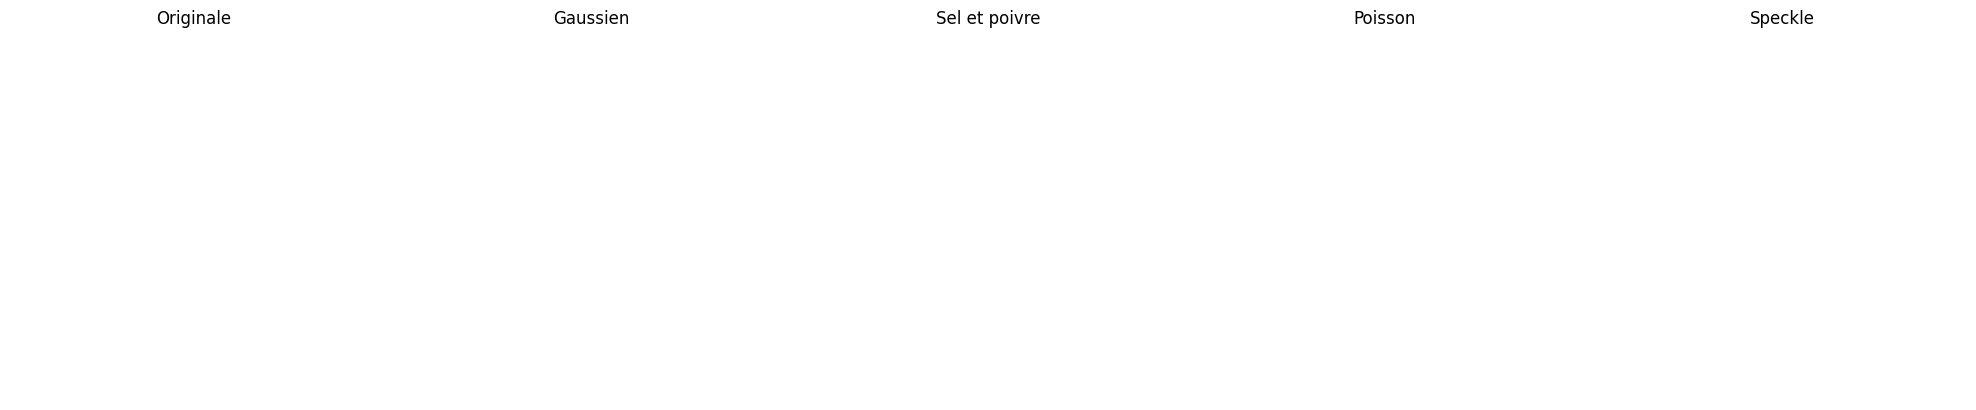

In [57]:
# Conversion en niveaux de gris : l'image devient un tableau 2D (hauteur, largeur)
# On utilise RGB2GRAY car notre image "img" est en RGB (pas en BGR)
img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("Dimensions de l'image grise :", img_gray.shape)   # plus de 3ème dimension

# On applique les 4 mêmes fonctions de bruit : elles fonctionnent aussi sur du 2D
gaussian_gray    = add_gaussian_noise(img_gray, sigma=40)
salt_pepper_gray = add_salt_pepper(img_gray, amount=0.03)
poisson_gray     = add_poisson_noise(img_gray)
speckle_gray     = add_speckle_noise(img_gray, sigma=0.20)

noisy_gray = [img_gray, gaussian_gray, salt_pepper_gray, poisson_gray, speckle_gray]
titles = ["Originale", "Gaussien", "Sel et poivre", "Poisson", "Speckle"]

# Image entière
show_images_gray(noisy_gray, titles, figsize=(20, 4))

# Zoom sur une petite zone pour mieux voir la nature de chaque bruit
# (adaptez ces valeurs à la taille de votre image : voir img_gray.shape)
y1, y2, x1, x2 = 400, 600, 500, 1000
show_images_gray([im[y1:y2, x1:x2] for im in noisy_gray], titles, figsize=(20, 4))

**Question C1** — Comparez les quatre bruits. Lequel produit des pixels isolés noirs/blancs ?

**Réponse C1 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question C2** — Le bruit de Poisson est-il simplement du bruit ajouté de la même manière que le bruit gaussien ? Observez son comportement dans les zones sombres et claires.

**Réponse C2 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question C3** — Pourquoi le speckle est-il appelé bruit multiplicatif ? *Indice : regardez la formule `x + x × bruit`.*

** Réponse C3 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

---
# Partie D — Débruitage et influence des paramètres

Appliquez différents filtres OpenCV et comparez leurs effets. Commencez par le **bruit gaussien** et le **bruit sel et poivre**.

### D1. Filtre moyenneur
Chaque pixel est remplacé par la **moyenne** de son voisinage `k × k`.

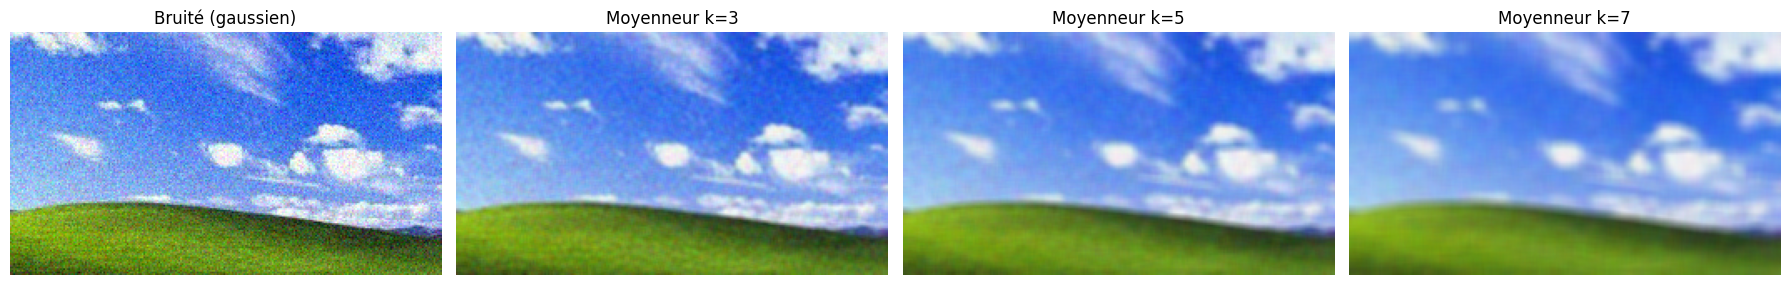

In [58]:
def mean_filter(img, k=3):
    """Filtre moyenneur : moyenne des pixels dans une fenêtre k x k."""
    return cv2.blur(img, (k, k))

# Test sur le bruit gaussien avec plusieurs tailles de noyau
ks = [3, 5, 7]
results = [mean_filter(gaussian, k) for k in ks]
show_images([gaussian] + results, ["Bruité (gaussien)"] + [f"Moyenneur k={k}" for k in ks], figsize=(18, 4))

### D2. Filtre gaussien
Comme le moyenneur, mais les pixels **proches du centre** comptent davantage (poids en forme de cloche). Deux paramètres : la taille du noyau `k` et l'écart-type `sigma`

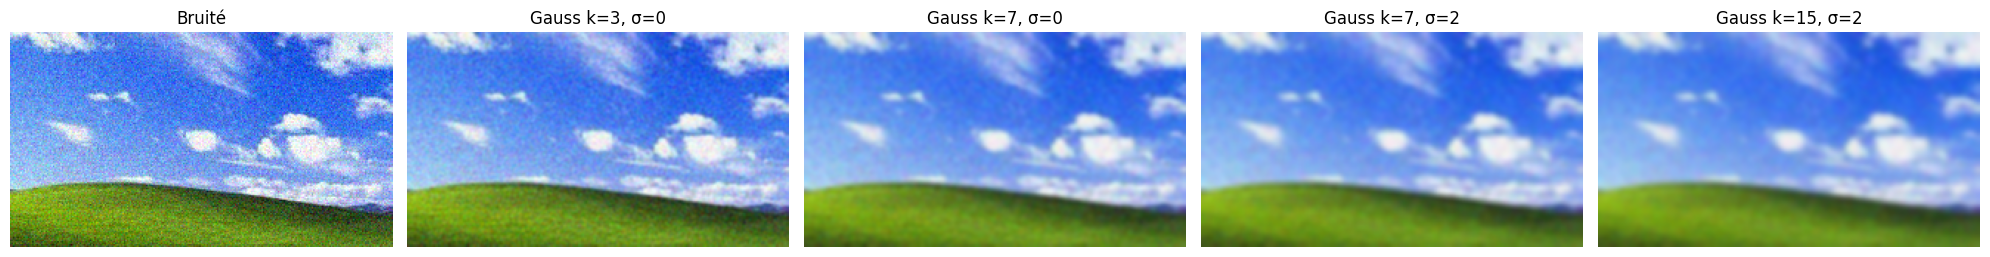

In [59]:
def gaussian_filter(img, k=5, sigma=0):
    """Filtre gaussien : moyenne pondérée par une gaussienne."""
    return cv2.GaussianBlur(img, (k, k), sigma)

# Test : plusieurs tailles de noyau ET deux valeurs de sigma (0 = automatique, et 2)
configs = [(3, 0), (7, 0), (7, 2), (15, 2)]
results = [gaussian_filter(gaussian, k, s) for k, s in configs]
show_images([gaussian] + results,
            ["Bruité"] + [f"Gauss k={k}, σ={s}" for k, s in configs], figsize=(20, 4))

### D3. Filtre médian
Chaque pixel est remplacé par la **médiane** des valeurs de son voisinage. Ce filtre est **non linéaire** : une valeur aberrante (très claire ou très sombre) n'influence pas la médiane.

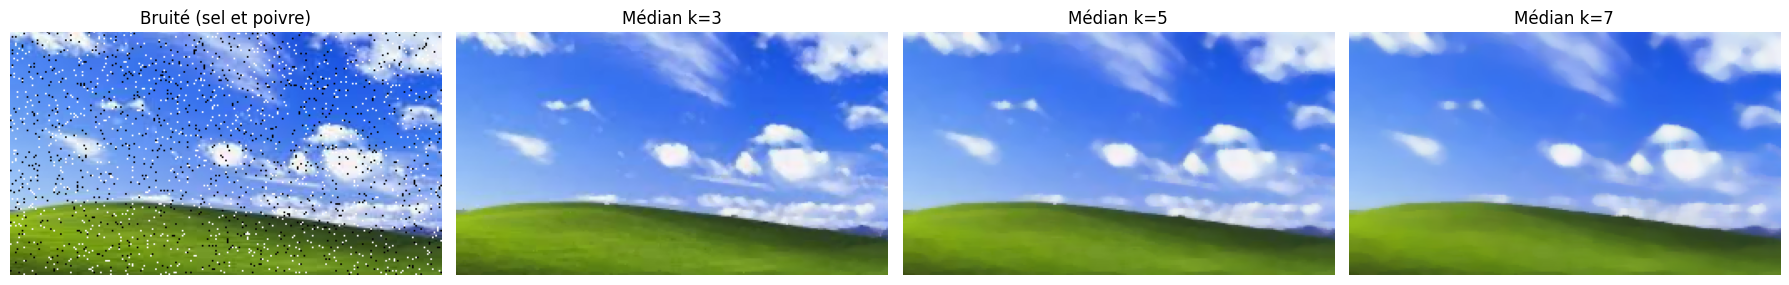

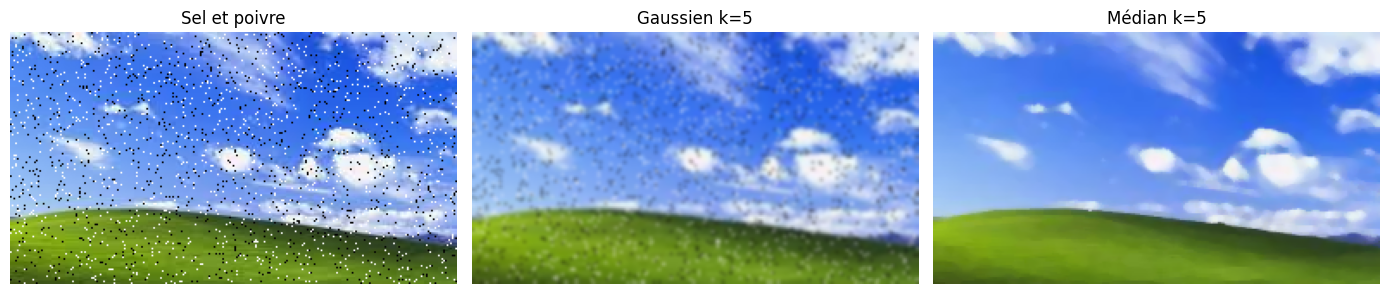

In [60]:
def median_filter(img, k=3):
    """Filtre médian : médiane des pixels dans une fenêtre k x k (k doit être impair)."""
    return cv2.medianBlur(img, k)

# Test sur le bruit sel et poivre avec k = 3, 5 et 7
ks = [3, 5, 7]
results = [median_filter(salt_pepper, k) for k in ks]
show_images([salt_pepper] + results, ["Bruité (sel et poivre)"] + [f"Médian k={k}" for k in ks], figsize=(18, 4))

# Comparaison directe : gaussien vs médian sur le même bruit sel et poivre
show_images(
    [salt_pepper, gaussian_filter(salt_pepper, 5), median_filter(salt_pepper, 5)],
    ["Sel et poivre", "Gaussien k=5", "Médian k=5"], figsize=(14, 4)
)

### D4. Padding (gestion des bords)
Les pixels proches des bords n'ont **pas un voisinage complet**. OpenCV doit donc "inventer" des pixels en dehors de l'image :
- `BORDER_REFLECT` : on **reflète** l'image comme dans un miroir.
- `BORDER_REPLICATE` : on **répète** le dernier pixel du bord.
- `BORDER_CONSTANT` : on complète avec une **constante** (0 = noir).

Ici on utilise un grand noyau (15×15) pour que les différences soient bien visibles.

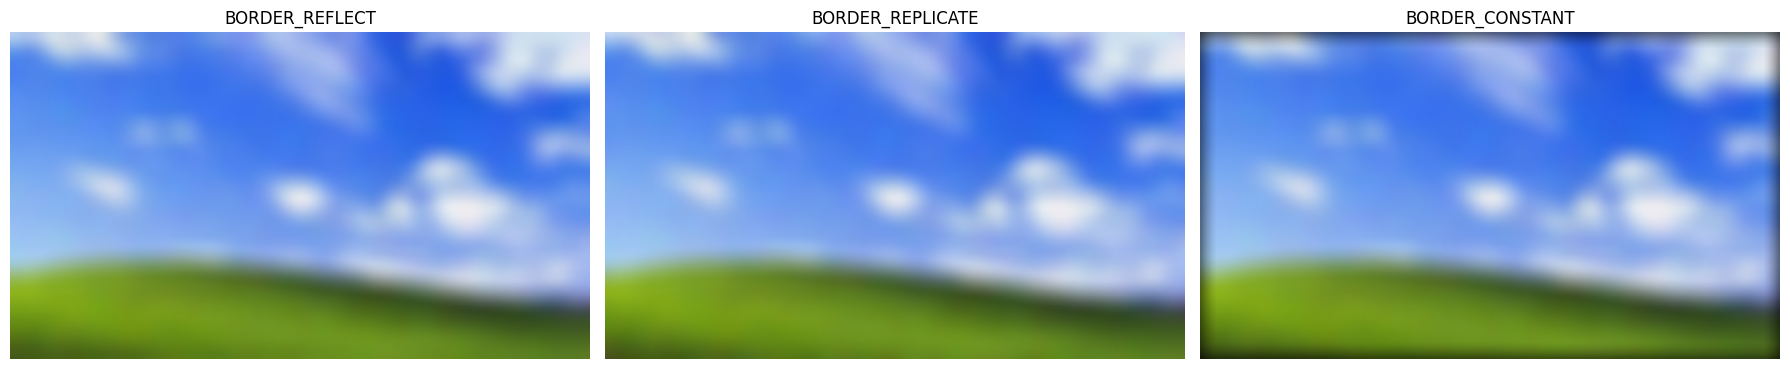

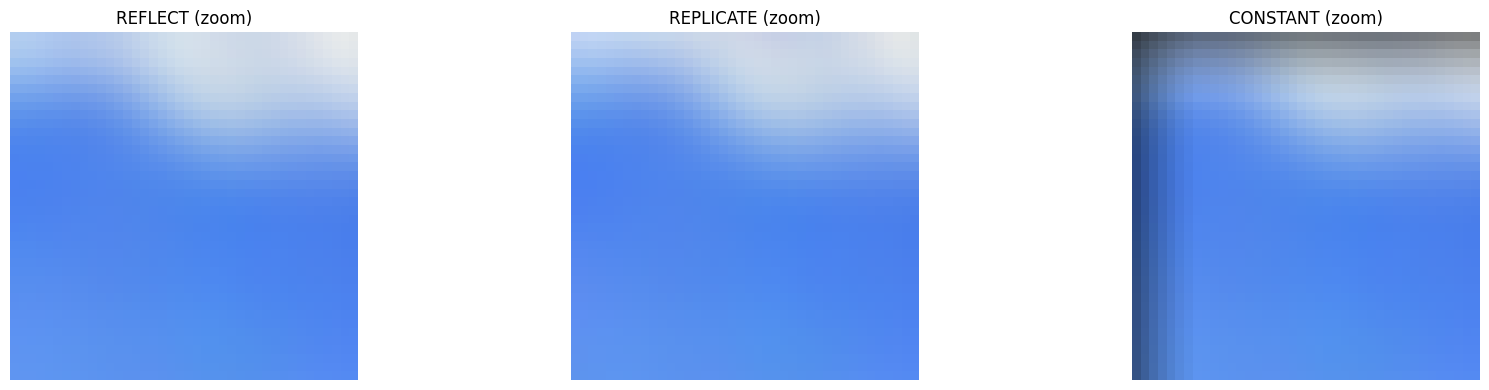

Écart moyen REFLECT vs CONSTANT sur toute l'image : 4.65
Écart moyen dans le coin 40x40                      : 14.46


In [61]:
k, sigma = 15, 5   # Grand noyau : l'effet de bord devient visible

out_reflect   = cv2.GaussianBlur(gaussian, (k, k), sigma, borderType=cv2.BORDER_REFLECT)
out_replicate = cv2.GaussianBlur(gaussian, (k, k), sigma, borderType=cv2.BORDER_REPLICATE)
out_constant  = cv2.GaussianBlur(gaussian, (k, k), sigma, borderType=cv2.BORDER_CONSTANT)

show_images([out_reflect, out_replicate, out_constant],
            ["BORDER_REFLECT", "BORDER_REPLICATE", "BORDER_CONSTANT"], figsize=(18, 4))

# Zoom sur le coin supérieur gauche (là où les bords comptent le plus)
c = 40
show_images([o[:c, :c] for o in [out_reflect, out_replicate, out_constant]],
            ["REFLECT (zoom)", "REPLICATE (zoom)", "CONSTANT (zoom)"], figsize=(18, 4))

# Mesure : écart moyen entre les résultats (0 = identiques)
diff = np.abs(out_reflect.astype(int) - out_constant.astype(int))
print("Écart moyen REFLECT vs CONSTANT sur toute l'image :", diff.mean().round(2))
print("Écart moyen dans le coin 40x40                      :", diff[:c, :c].mean().round(2))

**Question D1** — Quel est l'effet de l'augmentation de la taille du noyau ? Que gagne-t-on et que perd-on ?

**Réponse D1 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question D2** — Pourquoi utilise-t-on généralement des tailles impaires comme 3, 5 ou 7 pour les noyaux ?

**Réponse D2 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question D3** — Le filtre médian ou le filtre gaussien est-il le plus adapté au bruit sel et poivre ? Justifiez à partir de vos observations.

**Réponse D3 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question D4** — Les résultats sont-ils identiques près des bords avec les trois modes de padding ? Expliquez pourquoi.

**Réponse D4: **

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

---
# Partie E — Comparaison finale

Créez une figure comparant :
1. L'image originale
2. Bruit gaussien + **meilleur débruitage choisi**
3. Bruit sel et poivre + **meilleur débruitage choisi**
4. Bruit de Poisson + **meilleur débruitage choisi**
5. Speckle + **meilleur débruitage choisi**

Pour chaque cas, indiquez le **filtre** et les **paramètres** choisis.

Pour vous aider à justifier vos choix, vous pouvez calculer le **PSNR** (en dB) entre l'image originale et l'image débruitée : **plus il est élevé, plus l'image est proche de l'originale**.

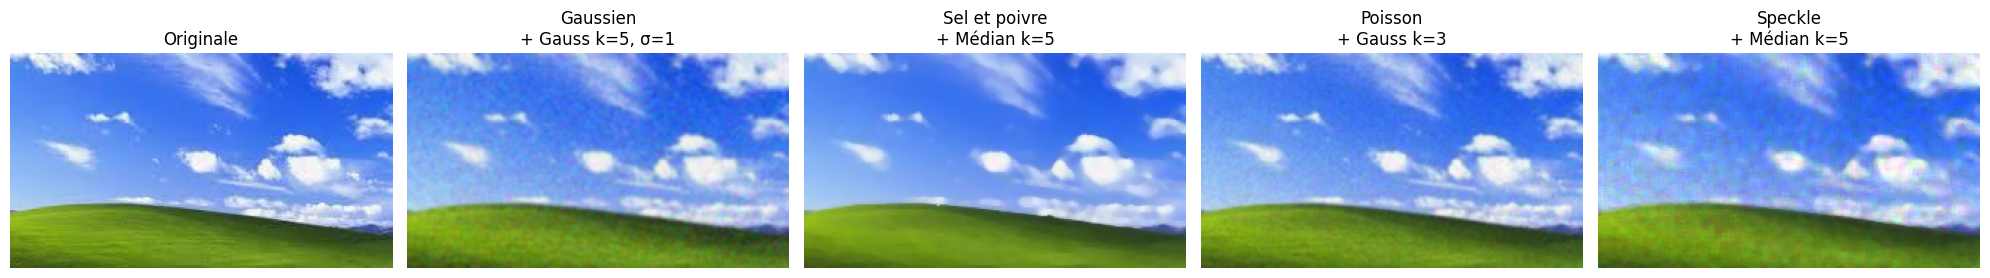

PSNR avant / après débruitage :
  Gaussien      : 22.52 dB  ->  30.13 dB
  Sel et poivre : 17.07 dB  ->  32.00 dB
  Poisson       : 26.94 dB  ->  32.57 dB
  Speckle       : 19.15 dB  ->  27.31 dB


In [62]:
# ====== À MODIFIER : choisissez vos filtres et paramètres d'après vos observations ======
# Les valeurs ci-dessous ne sont que des exemples de départ, testez-en d'autres !
den_gaussian    = gaussian_filter(gaussian, k=5, sigma=1)    # Filtre choisi pour le bruit gaussien
den_salt_pepper = median_filter(salt_pepper, k=5)            # Filtre choisi pour le sel et poivre
den_poisson     = gaussian_filter(poisson, k=3, sigma=0)     # Filtre choisi pour Poisson
den_speckle     = median_filter(speckle, k=5)                # Filtre choisi pour le speckle
# =========================================================================================

# Descriptions affichées dans les titres (à mettre à jour si vous changez les filtres ci-dessus)
titles = [
    "Originale",
    "Gaussien\n+ Gauss k=5, σ=1",
    "Sel et poivre\n+ Médian k=5",
    "Poisson\n+ Gauss k=3",
    "Speckle\n+ Médian k=5",
]
images = [img, den_gaussian, den_salt_pepper, den_poisson, den_speckle]
show_images(images, titles, figsize=(20, 5))

# PSNR : comparaison objective avec l'image originale (en dB, plus c'est haut, mieux c'est)
print("PSNR avant / après débruitage :")
for name, noisy, den in [("Gaussien", gaussian, den_gaussian),
                         ("Sel et poivre", salt_pepper, den_salt_pepper),
                         ("Poisson", poisson, den_poisson),
                         ("Speckle", speckle, den_speckle)]:
    print(f"  {name:14s}: {cv2.PSNR(img, noisy):5.2f} dB  ->  {cv2.PSNR(img, den):5.2f} dB")

---
## Questions de synthèse

**Question 1** — Existe-t-il un filtre universel qui supprime efficacement tous les types de bruit ? Pourquoi ?

**Réponse S1 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question 2** — Quel compromis apparaît lorsque l'on augmente fortement la taille du noyau ?

**Réponse S2 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question 3** — Pourquoi le débruitage peut-il être bénéfique mais aussi nuisible pour une tâche de vision par ordinateur ?

**Réponse S3 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

**Question 4** — Quelle différence faites-vous entre 'type de bruit', 'filtre de débruitage' et 'paramètre du filtre' ?

** Réponse S4 :**

*(écrivez votre réponse ici en double-cliquant sur cette cellule)*

---
## À rendre Avant 23/10/26
Ce notebook complété (`.ipynb`) contenant **les traitements, les figures obtenues et des réponses courtes aux questions**.

Le fichier doit être nommé selon le format suivant :

Nom1_Nom2_GroupeX.ipynb


Avant l'envoi, vérifiez que :

toutes les cellules ont été exécutées,
les résultats et les figures sont visibles,
les réponses aux questions sont complétées,
le fichier s'ouvre correctement.

Le fichier doit être envoyé par e-mail: w.abouzbiba@emsi.ma

Objet de l'e-mail :
TP1 - Groupe X - Nom1 Nom2

